# Task for session2_cont and session3: 
## Edge-Preserving Denoising Filters & Feature Matching

**Instructions:**  
**please dont use .py to solve this task, just use tasks2.ipynb and edit the cells.**
- After forking the [SkyXperts-Vision-Course repo](https://github.com/ffathy-tdx/SkyXperts-Vision-Course) on GitHub. (you should have already dont this in the last session & uploaded task1)
- Go to your fork of the repo on GitHub.
- At the top, look for a yellow box that says “This branch is X commits behind…”
- Click the Sync fork or Update branch button.
The new task will show up in your tasks/ folder.  
- Upload your task to your forked repo (like you've done with task1 before)
---

## 1. DoG, LoG, and Edge-Preserving Denoising Filters

**Task:**
- Briefly read the descriptions below, then apply each filter to `'sample.jpg'` (or any test image you choose).
- Compare the results visually and write your observations.

**Background:**
- **DoG (Difference of Gaussian):** Used for edge detection by subtracting two blurred versions of the image (with different Gaussian sigmas).
- **LoG (Laplacian of Gaussian):** Uses a single Gaussian blur followed by Laplacian to highlight regions of rapid intensity change (edges).
- **Edge-Preserving Denoising (Bilateral Filter):** Smooths image while preserving edges (unlike simple Gaussian blur). You've already used this at the end of task1.

---

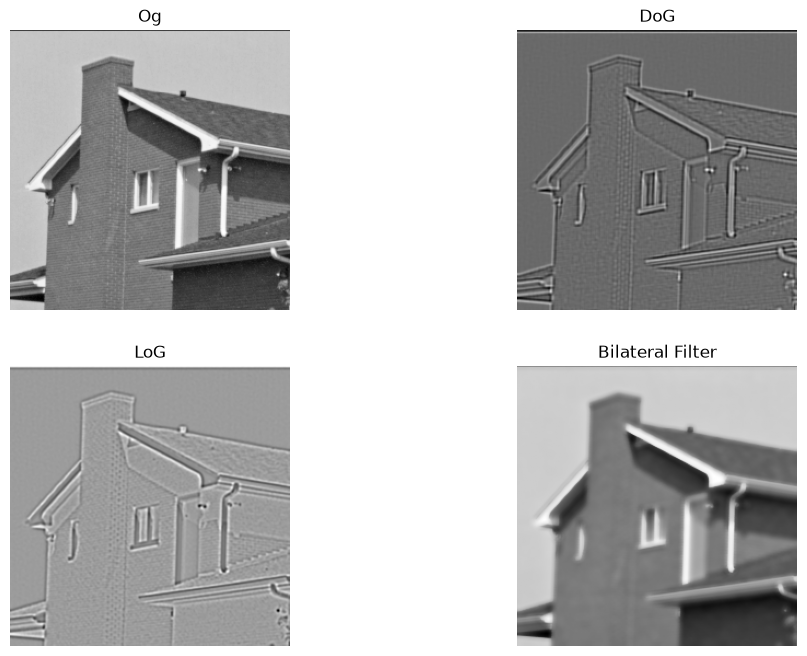

In [14]:
# Import required libraries
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

# Load image
img = cv.imread(r"D:\SkyXperts-Vision-Course\tasks\test images\4.1.05.tiff", 0)  # Use grayscale for filtering
assert img is not None, "Image not found. Please check the path."
img =img.astype(np.float32)  # 8aleban dy hatb2a el bug WHAT matl3tsh hia nvm hia
#img=cv.cvtColor(img, cv.COLOR_BGR2GRAY)  
# TODO: Apply DoG
DoG = cv.GaussianBlur(img, (5, 5), 2) - cv.GaussianBlur(img, (5, 5), 3) #n5tafha mara wa7da 
# TODO: Apply LoG
LoG = cv.Laplacian(cv.GaussianBlur(img, (5, 5), 1), cv.CV_32F)
# TODO: Apply bilateral (edge-preserving) filter
bilateral = cv.bilateralFilter(img, 9, 75, 75)
cv.imshow("blurred",cv.GaussianBlur(img, (5, 5), 2))
cv.waitKey(0)
cv.destroyAllWindows()
# Show all results for comparison
plt.figure(figsize=(12, 8))
plt.subplot(2, 2, 1)
plt.imshow(img, cmap='gray'); plt.axis('off'); plt.title('Og')
plt.subplot(2, 2, 2)
plt.imshow(DoG, cmap='gray'); plt.axis('off'); plt.title('DoG')
plt.subplot(2, 2, 3)
plt.imshow(LoG, cmap='gray'); plt.axis('off'); plt.title('LoG')
plt.subplot(2, 2, 4)
plt.imshow(bilateral, cmap='gray'); plt.axis('off'); plt.title('Bilateral Filter')
plt.show()

**Q1: What differences do you observe between DoG, LoG, and the edge-preserving filter?**

_Write your observations here._


DoG preserves edges but its output image is too noisy (it contains salt pixels)


ta3deel: i forgot to convert the img into float so the negative values wrapped around and created noise 

so it is obvious that dog is somewhat close to the original but it lacks some color depth although the shapes are very clear


LoG img looks like microscopic bacteria but the image edges are visible tho it doesn't carry any color and i think the black sots inside the circles are noise which would make sense yarab yb2o noise f3lan 



bilateral filter blurs the image but edges are still very clear

overall the three filters preserved the edges and there were no distortions 

## 2. Keypoints & Descriptors: SIFT vs. ORB

**Task:**
- Detect and plot keypoints on `'sample.jpg'` using SIFT and ORB.
- Compare the number and distribution of detected keypoints.

**Background:**
- **Keypoints:** Distinctive image points (corners/blobs) useful for matching.
- **Descriptors:** Vectors that describe local patches around keypoints for comparison/matching.

---

201 376


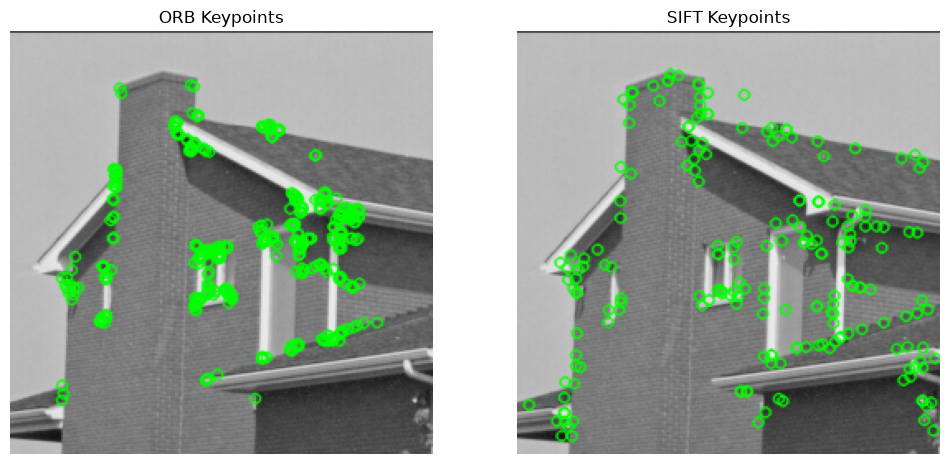

In [16]:
# Detect and plot SIFT keypoints
sift = cv.SIFT_create()

# Detect and plot ORB keypoints
orb = cv.ORB_create()
#hna bn create the objects

# TODO: Count and compare number of keypoints for SIFT and ORB
#only keypoints here so 
#turns out i need to convert the image type again 
new_img = img.astype(np.uint8)
siftk =sift.detect(new_img, None)
orbk =orb.detect(new_img, None)  #None here means that the whole image is used for detection 
#now we have the keypoints we can count them
print(len(siftk),len(orbk))
#now i want to compare their distributions so 
orb_img = cv.drawKeypoints(new_img, orbk, None, color=(0, 255, 0), flags=0)
sift_img = cv.drawKeypoints(new_img, siftk, None, color=(0, 255, 0), flags=0)
#now i want to show them
plt.figure(figsize=(12, 8))
plt.subplot(1, 2, 1) 
plt.imshow(orb_img); plt.axis('off'); plt.title('ORB Keypoints')
plt.subplot(1, 2, 2)
plt.imshow(sift_img); plt.axis('off'); plt.title('SIFT Keypoints')
plt.show()


**Q2: How do the number and distribution of keypoints differ between SIFT and ORB?**

_Write your answer here._

ORB generated about two times the keypoints of SIFT , its keypoints are concentrated around specific areas.

SIFT's keypoints are more spatially distributed and cover more area along the edges, it looks like it may be more representative than ORB in this image sample.

## 3. Feature Matching with Descriptors

**Task:**
- Load a second image (e.g., `'sample2.jpg'`).
- Detect keypoints/descriptors using SIFT or ORB in both images.
- Match the features between the images using BFMatcher or FLANN.
- Plot the top matches.

**Background:**
- **Feature matching** helps recognize objects/scenes or estimate image transformations.

---

Good matches: 5


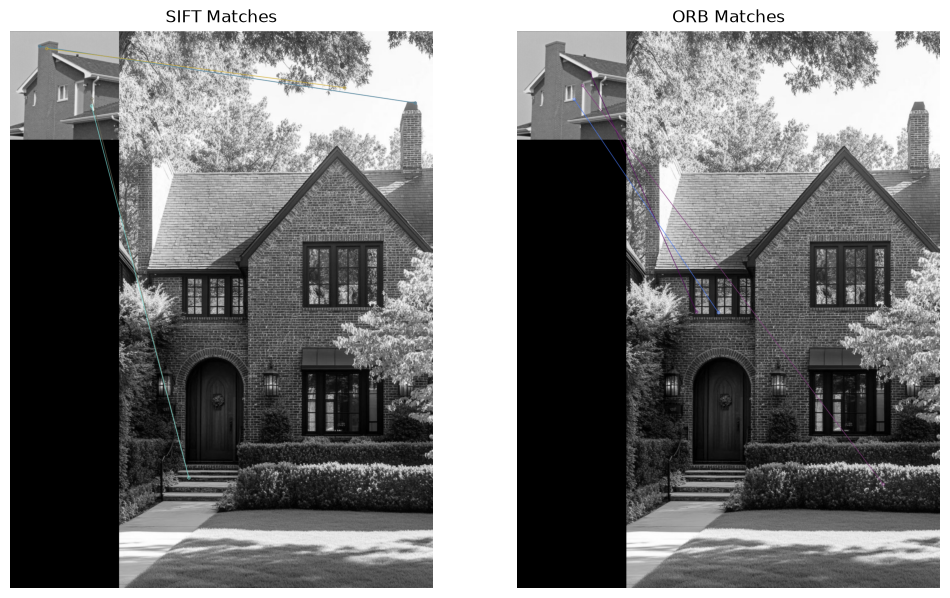

In [31]:
# Load second image
img2 = cv.imread(r"D:\SkyXperts-Vision-Course\tasks\test images\Get Inspired_ Exterior House Makeover Ideas.jfif", 0)
# Detect SIFT keypoints/descriptors in both images
#now we use detectAndCompute to get both keypoints and descriptors
h, w = new_img.shape[:2]
center = (w / 2, h / 2)
M = cv.getRotationMatrix2D(center, 30, 1.0)  
rotated = cv.warpAffine(img, M, (w, h))   
kp1, des1 = sift.detectAndCompute(new_img, None)
if img2 is None:
    raise FileNotFoundError("Could not load the second image; check its path.")

img2 = np.ascontiguousarray(img2, dtype=np.uint8)
kp2, des2 = sift.detectAndCompute(img2, None)

if des1 is None or des2 is None:
    raise ValueError("SIFT found no descriptors in one of the images.")
# BFMatcher with default params
bf = cv.BFMatcher()
# Match descriptors
matches = bf.knnMatch(des1, des2, k=2) #use k=2 for ratio test 3shan a2dar ashoof which matches are good enough to pass 
# Draw matches now
good_matches = [
    m for m, n in matches
    if m.distance < 0.75 * n.distance #bashoof if the match is good enough to pass the ratio test
]
good_matches = sorted(good_matches, key=lambda match: match.distance)[:50]

print(f"Good matches: {len(good_matches)}")
img_matches = cv.drawMatches(
    new_img, kp1, img2, kp2, good_matches, None,
    flags=cv.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)
# bonus TODO: Try with ORB or FLANN if you like
#do the same with orb 
kp3, des3 = orb.detectAndCompute(new_img, None)
kp4, des4 = orb.detectAndCompute(img2, None)
#i want to use flann based matcher for orb
FLANN_INDEX_LSH = 6
index_params = dict(
    algorithm=FLANN_INDEX_LSH,
    table_number=6,
    key_size=12,
    multi_probe_level=1
)
search_params = dict(checks=50)
flann = cv.FlannBasedMatcher(index_params, search_params)
matches_orb = flann.knnMatch(des3, des4, k=2)
good_matches_orb = [
 m for m, n in matches_orb              
if m.distance < 0.75 * n.distance
]
good_matches_orb = sorted(good_matches_orb, key=lambda match: match.distance)
#i want to display both 
plt.figure(figsize=(12, 8))
plt.subplot(1, 2, 1)
plt.imshow(img_matches); plt.axis('off'); plt.title('SIFT Matches')
img_matches_orb = cv.drawMatches(
    new_img, kp3, img2, kp4, good_matches_orb, None,
    flags=cv.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)
plt.subplot(1, 2, 2)
plt.imshow(img_matches_orb); plt.axis('off'); plt.title('ORB Matches')
plt.show()

**Q3: What do you notice about the feature matches? Are there any mismatches or errors? How might you improve the matching process?**

_Write your answer here._

There are generally very few matches because i used different images featuring a house mmkn agarab a3ml rotation l awl wa7da w 5alas and THEY ARE NOT ACCURATE 

Good matches: 50


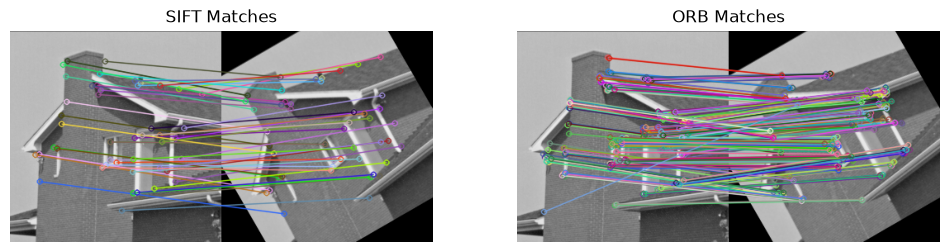

In [40]:
  # Detect SIFT keypoints/descriptors in both images
#now we use detectAndCompute to get both keypoints and descriptors
h, w = new_img.shape[:2]
center = (w / 2, h / 2)
M = cv.getRotationMatrix2D(center, 30, 1.0)
rotated = cv.warpAffine(new_img, M, (w, h))

kp1, des1 = sift.detectAndCompute(new_img, None)
kp2, des2 = sift.detectAndCompute(rotated, None)
# BFMatcher with default params
bf = cv.BFMatcher()
# Match descriptors
matches = bf.knnMatch(des1, des2, k=2) #use k=2 for ratio test 3shan a2dar ashoof which matches are good enough to pass 
# Draw matches now
good_matches = [
    m for m, n in matches
    if m.distance < 0.75 * n.distance #bashoof if the match is good enough to pass the ratio test
]
good_matches = sorted(good_matches, key=lambda match: match.distance)[:50]

print(f"Good matches: {len(good_matches)}")
img_matches = cv.drawMatches(
    new_img, kp1, rotated, kp2, good_matches, None,
    flags=cv.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)
# bonus TODO: Try with ORB or FLANN if you like
#do the same with orb 
kp3, des3 = orb.detectAndCompute(new_img, None)
kp4, des4 = orb.detectAndCompute(rotated, None)
#i want to use flann based matcher for orb
FLANN_INDEX_LSH = 6
index_params = dict(algorithm=FLANN_INDEX_LSH, table_number=6, key_size=12, multi_probe_level=1)
search_params = dict(checks=50)
flann = cv.FlannBasedMatcher(index_params, search_params)
matches_orb = flann.knnMatch(des3, des4, k=2)
good_matches_orb = [ m for m, n in matches_orb              
if m.distance < 0.75 * n.distance
]
good_matches_orb = sorted(good_matches_orb, key=lambda match: match.distance)
#i want to display both 
plt.figure(figsize=(12, 8))
plt.subplot(1, 2, 1)
plt.imshow(img_matches); plt.axis('off'); plt.title('SIFT Matches')
img_matches_orb = cv.drawMatches(
    new_img, kp3, rotated, kp4, good_matches_orb, None,
    flags=cv.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
)
plt.subplot(1, 2, 2)
plt.imshow(img_matches_orb); plt.axis('off'); plt.title('ORB Matches')
plt.show()
   

Now there is plenty of matches a obviously AGAIN ORB made more matches than SIFT (same observation from the keypoints on the single image)

**Bonus Task (Optional, for extra credit):**
- Try using different image preprocessing steps *before* edge detection or feature extraction.
    - For example:
        - Add noise to your image (e.g., Gaussian noise, salt-and-pepper noise).
        - Apply a sharpening filter to your image.
    - Then, run DoG, LoG, or any edge-preserving filter and observe the changes.
- **What to do:**
    - Show the results (images/plots) for at least one type of preprocessing + edge detection.
    - Briefly explain:
        - How does noise affect edge maps or keypoints?
        - Does sharpening make features easier or harder to detect/match?

**You can add your code and observations in the cells below.**


In [51]:
# Write your code here
#first read the image and convert it to grayscale 
img = cv.imread(r"D:\SkyXperts-Vision-Course\tasks\test images\Get Inspired_ Exterior House Makeover Ideas.jfif", 0)

#now add the noise 
noise = np.random.normal(0, 25, img.shape).astype(np.float32) #i added slight noise

noisy_img = np.clip(
    img.astype(np.float32) + noise,
    0, 255
).astype(np.float32)

smooth = cv.GaussianBlur(noisy_img, (5, 5), 1)

#now the sharpenning filter
sharpened = cv.addWeighted(
    noisy_img, 1.5,
    smooth, -0.5,
    0
)

#ha apply gaussian blur 3la el sharpened img 
blurred = cv.GaussianBlur(sharpened, (5, 5), 3)
blurred2 = cv.GaussianBlur(sharpened, (5, 5), 4)

DoG = blurred2 - blurred

LoG = cv.Laplacian(blurred, cv.CV_64F) #again b2a 3la el blur 

#now i will display w ha keep el pipeline as filters not feature detection 3shan lsa 3amlaha fo2 
plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
plt.imshow(noisy_img, cmap='gray', vmin=0, vmax=255)
plt.axis('off')
plt.title('Noisy Image')

plt.subplot(2, 2, 2)
limit = np.max(np.abs(DoG))
plt.imshow(DoG, cmap='gray', vmin=-limit, vmax=limit)
plt.axis('off')
plt.title('DoG')

plt.subplot(2, 2, 3)
limit = np.max(np.abs(LoG))
plt.imshow(LoG, cmap='gray', vmin=-limit, vmax=limit)
plt.axis('off')
plt.title('LoG')

plt.subplot(2, 2, 4)
plt.imshow(blurred, cmap='gray', vmin=0, vmax=255)
plt.axis('off')
plt.title('Gaussian Blur')

plt.tight_layout()
plt.show()

error: OpenCV(5.0.0) D:/a/opencv-python/opencv-python/opencv/modules/imgproc/src/filter.simd.hpp:3541: error: (-213:The function/feature is not implemented) Unsupported combination of source format (=5), and destination format (=6) in function 'cv::opt_AVX2::getLinearFilter'


_What are your observations?_
write them here

## 4. Reflection (Optional)

- What was the most challenging or interesting part of this task for you?
- Any feedback or thoughts?

_Write your reflection here._

THE BUGS ARE GENUINELY FRUSTRATING W MALHASH MA7AL MN EL E3RAB bs zy el fol 